# Audio — Klasifikasi dengan Embedding wav2vec2
**Kapan dipakai:** klasifikasi klip suara yang lebih sulit dari MFCC (ucapan, nada, aksen).
Model wav2vec2 sudah belajar dari ribuan jam suara, jadi feature-nya jauh lebih kaya.

**Idenya:** wav2vec2 (tanpa dilatih ulang) mengubah klip menjadi 768 angka (embedding),
lalu model sklearn biasa belajar dari angka-angka itu.

**Langkah:**
1. Ubah tiap klip menjadi embedding (rata-rata hidden state di sumbu waktu).
2. Latih model, evaluasi di data validasi.
3. Latih ulang di semua data train, simpan submission.

**Data demo:** Speech Commands mini (8 kata).

In [1]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from transformers import AutoFeatureExtractor, Wav2Vec2Model

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/audio/classification"   # GANTI saat lomba
DATA_FOLDER = f"{DATA_FOLDER}/speech_commands_mini"
# Data speaker (label = ID speaker, kolom tetap `path` dan `label`):
# DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/audio/speaker/speech_commands_speakers"
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
PRETRAINED_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/wav2vec2_base"

ID_COL = "id"
PATH_COL = "path"           # kolom berisi nama file audio, relatif terhadap DATA_FOLDER
LABEL_COL = "label"
SAMPLE_RATE = 16000         # wav2vec2 dilatih dengan 16000 sampel per detik
CLIP_LENGTH = 16000         # 1 detik per klip
BATCH_SIZE = 32             # kecilkan bila memori GPU penuh
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print(train.shape, test.shape)
print(train.isna().sum())
train.head()

(1200, 3) (320, 3)
path       0
label      0
speaker    0
dtype: int64


,path,label,speaker
0,train/down/7ff085e1_nohash_0.wav,down,7ff085e1
1,train/down/39543cfd_nohash_0.wav,down,39543cfd
2,train/down/3bc21161_nohash_4.wav,down,3bc21161
3,train/down/2f666bb2_nohash_0.wav,down,2f666bb2
4,train/down/bc196f81_nohash_0.wav,down,bc196f81


## EDA: jumlah klip per kelas

label
down     150
go       150
left     150
no       150
right    150
stop     150
up       150
yes      150
Name: count, dtype: int64


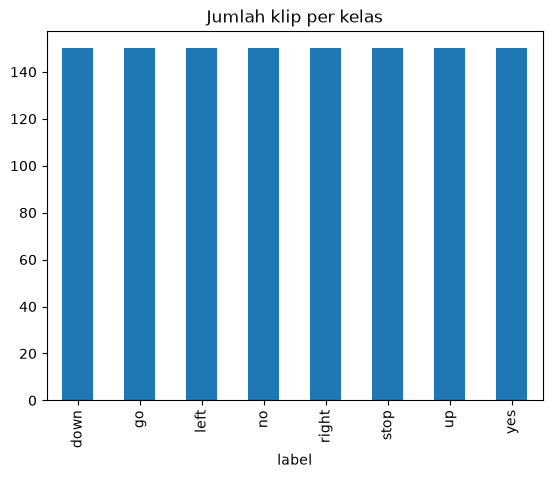

In [4]:
class_counts = train[LABEL_COL].value_counts()
print(class_counts)
class_counts.plot.bar(title="Jumlah klip per kelas")
plt.show()

## Langkah 1 — embedding wav2vec2
`load_clip` membaca satu file dan menyamakan panjangnya. `extract_embeddings` memproses klip
per batch: hidden state wav2vec2 (satu vektor per 20 ms) dirata-rata menjadi satu vektor.

In [5]:
feature_extractor = AutoFeatureExtractor.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder = Wav2Vec2Model.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder.eval()
encoder = encoder.to(DEVICE)


def load_clip(path):
    audio, _ = librosa.load(f"{DATA_FOLDER}/{path}", sr=SAMPLE_RATE)
    audio = np.pad(audio, (0, CLIP_LENGTH))     # tambah nol di belakang
    return audio[:CLIP_LENGTH]                  # lalu potong tepat 1 detik


def extract_embeddings(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        clips = []
        for path in paths[start:start + BATCH_SIZE]:
            clips.append(load_clip(path))
        inputs = feature_extractor(clips, sampling_rate=SAMPLE_RATE, return_tensors="pt")
        with torch.no_grad():
            output = encoder(inputs.input_values.to(DEVICE))
        mean_over_time = output.last_hidden_state.mean(dim=1)
        batches.append(mean_over_time.cpu().numpy())
    return np.concatenate(batches)


# coba pada 2 klip
example = extract_embeddings(list(train[PATH_COL][:2]))
print("ukuran embedding 2 klip:", example.shape)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: Z:/GEMASTIK-DATABASE/pretrained/wav2vec2_base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ukuran embedding 2 klip: (2, 768)


In [6]:
X = extract_embeddings(list(train[PATH_COL]))
X_test = extract_embeddings(list(test[PATH_COL]))
y = train[LABEL_COL]
print(X.shape, X_test.shape)

(1200, 768) (320, 768)


## Split validasi

In [7]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y,
                                                  random_state=SEED)

## Langkah 2 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [8]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))   # kuat untuk embedding
# model = make_pipeline(StandardScaler(), SVC(C=10, random_state=SEED))
# model = make_pipeline(StandardScaler(), LGBMClassifier(verbose=-1, random_state=SEED))
# model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
# model = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=500,
#                                                                random_state=SEED))
# model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(256,),
#                                                       max_iter=1000, random_state=SEED))

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](8,)","['down','go','left',...,'stop','up','yes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Evaluasi (validasi dari data train)

F1 macro: 0.8748987914203601
              precision    recall  f1-score   support

        down       0.87      0.90      0.89        30
          go       0.93      0.87      0.90        30
        left       0.84      0.87      0.85        30
          no       0.82      0.90      0.86        30
       right       0.86      0.83      0.85        30
        stop       0.96      0.80      0.87        30
          up       0.90      0.87      0.88        30
         yes       0.85      0.97      0.91        30

    accuracy                           0.88       240
   macro avg       0.88      0.88      0.87       240
weighted avg       0.88      0.88      0.87       240



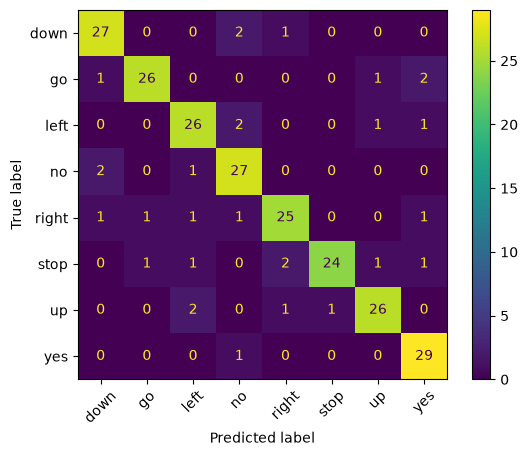

In [9]:
pred_val = model.predict(X_val)
print("F1 macro:", f1_score(y_val, pred_val, average="macro"))
# soal 2 kelas: print("F1 biner:", f1_score(y_val, pred_val, pos_label="nama_kelas_positif"))
print(classification_report(y_val, pred_val))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, xticks_rotation=45)
plt.show()

## Langkah 3 — latih ulang di semua data + submission

In [10]:
model.fit(X, y)
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test[ID_COL]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,1,down
1,2,down
2,3,down
3,4,down
4,5,down
